# Numerai: RFR с опорными точками LHS

Сравнение **RFR_LHS**, Ridge и LightGBM на одной обучающей выборке из 114 800 строк,
42 признаках `small` и цели `target_ender_60`. Для RFR используем **128 опорных точек**,
seed=42, ridge-регрессию коэффициентов с alpha=0.1, свободным членом и исходной `Kf`.
Признаки оставлены в исходном масштабе; пропуски заполняются медианами train.

Границы LHS вычислены только по train. Реконструкция обучающей выборки проверена
совпадением повторно обученных коэффициентов Ridge с сохранённой базовой моделью.
Параметры RFR зафиксированы заранее; подбора по validation нет.

Оценка — официальный Numerai CORR на тех же полных 640 эрах после промежутка
в 13 недель. Метрики Ridge и LightGBM взяты из первого эксперимента; совпадение
эр и числа строк проверено. CORR Sharpe не годовой. Накопленный CORR — не доходность.

[Описание CORR](https://docs.numer.ai/numerai-tournament/scoring/correlation-corr)


In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'experiments' / 'numerai_baselines.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'experiments' / 'numerai_baselines.py').exists()
RESULTS = ROOT / 'experiments' / 'results' / 'numerai_rfr'
plt.rcParams['figure.figsize'] = (12, 4)


## Повторный запуск

Ноутбук по умолчанию читает готовые результаты. Для повторного обучения выбери
интерпретатор `.venv/Scripts/python.exe` и установи `RUN_TRAINING=True`. Скрипт
использует сохранённые результаты и модель Ridge из первого эксперимента.

```powershell
.\.venv\Scripts\python.exe experiments\numerai_rfr.py
```

Повторный запуск перезапишет результаты RFR; исходные результаты базовых моделей
останутся в `experiments/results/numerai_baselines/`.


In [2]:
RUN_TRAINING = False
if RUN_TRAINING:
    sys.path.insert(0, str(ROOT / 'experiments'))
    from numerai_rfr import run
    run()


In [3]:
run_info = json.loads((RESULTS / 'run_config.json').read_text(encoding='utf-8'))
config = run_info['baseline_config'].copy()
config['fit_seconds'] = dict(config['fit_seconds'], RFR_LHS=run_info['fit_seconds'])
summary = pd.read_csv(RESULTS / 'summary.csv', index_col='model')
scores = pd.read_csv(RESULTS / 'per_era_corr.csv', index_col='era')
periods = pd.read_csv(RESULTS / 'period_summary.csv')
display(pd.Series({
    'target': config['target'],
    'features': config['feature_count'],
    'train_rows': config['training']['rows'],
    'train_eras': config['training']['era_count'],
    'train_era_range': (config['training']['first_era'], config['training']['last_era']),
    'validation_rows': config['validation']['rows'],
    'validation_eras': config['validation']['era_count'],
    'validation_era_range': (config['validation']['first_era'], config['validation']['last_era']),
    'skipped_validation_rows': config['validation']['skipped'],
    'fit_seconds': config['fit_seconds'],
}))
display(summary.round(6))

display(pd.Series(run_info['rfr_parameters']))


target                                                       target_ender_60
features                                                                  42
train_rows                                                            114800
train_eras                                                               574
train_era_range                                                     (1, 574)
validation_rows                                                      4003128
validation_eras                                                          640
validation_era_range                                             (588, 1227)
skipped_validation_rows    {'gap_rows': 75468, 'non_validation_rows': 908...
fit_seconds                {'Ridge': 0.6870000000053551, 'LightGBM': 12.2...
dtype: object

,eras,mean_corr,std_corr,corr_sharpe,positive_era_fraction,worst_era_corr,max_drawdown_cumulative_corr
model,,,,,,,
Ridge,640,0.012739,0.014339,0.888382,0.818750,-0.022942,0.109973
LightGBM,640,0.012025,0.014570,0.825292,0.782812,-0.035599,0.220092
RFR_LHS,640,0.012926,0.014020,0.921993,0.829688,-0.021192,0.099499


n_support             128
random_state           42
method_reg          ridge
alpha                 0.1
batch_size           1024
fit_intercept        True
C                       1
n                100000.0
t                100000.0
sig                   0.0
dtype: object

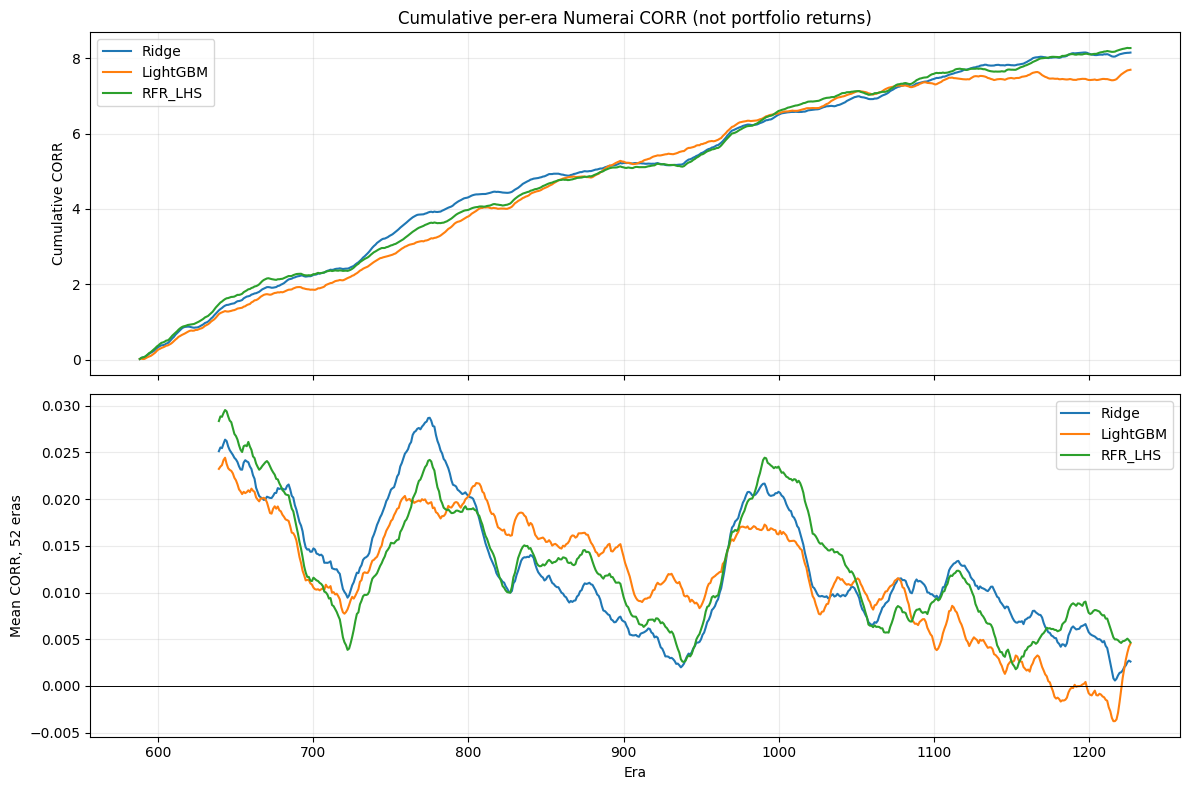

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
scores[['Ridge', 'LightGBM', 'RFR_LHS']].cumsum().plot(ax=axes[0])
axes[0].set_ylabel('Cumulative CORR')
axes[0].set_title('Cumulative per-era Numerai CORR (not portfolio returns)')
scores[['Ridge', 'LightGBM', 'RFR_LHS']].rolling(52, min_periods=52).mean().plot(ax=axes[1])
axes[1].axhline(0, color='black', linewidth=0.7)
axes[1].set_ylabel('Mean CORR, 52 eras')
axes[1].set_xlabel('Era')
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(RESULTS / 'corr_over_time.png', dpi=150)
plt.show()


## Стабильность во времени

Две половины валидации показаны отдельно. Это описательная проверка, а не наборы
для настройки параметров. Соседние эры имеют перекрывающиеся целевые горизонты:
их нельзя считать независимыми для простых оценок статистической значимости.

,model,eras,mean_corr,std_corr,corr_sharpe,positive_era_fraction,worst_era_corr,max_drawdown_cumulative_corr,period
0,Ridge,320,0.016303,0.014829,1.099338,0.865625,-0.018219,0.052709,earlier_half
1,LightGBM,320,0.016226,0.013952,1.163002,0.853125,-0.024202,0.085814,earlier_half
2,RFR_LHS,320,0.015953,0.014241,1.120177,0.865625,-0.020305,0.044244,earlier_half
3,Ridge,320,0.009175,0.012880,0.712296,0.771875,-0.022942,0.109973,later_half
4,LightGBM,320,0.007824,0.013951,0.560782,0.712500,-0.035599,0.220092,later_half
5,RFR_LHS,320,0.009900,0.013114,0.754889,0.793750,-0.021192,0.099499,later_half


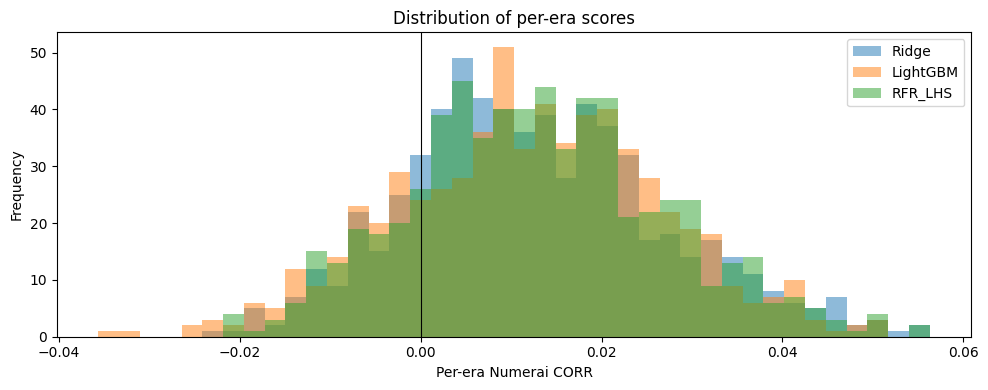

In [5]:
display(periods.round(6))
fig, ax = plt.subplots(figsize=(10, 4))
scores[['Ridge', 'LightGBM', 'RFR_LHS']].plot.hist(bins=40, alpha=0.5, ax=ax)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Per-era Numerai CORR')
ax.set_title('Distribution of per-era scores')
fig.tight_layout()
plt.show()


## Интерпретация

Это первый фиксированный запуск RFR_LHS с исходной Kf. Сравнение использует одни
и те же строки и эры, но преобразования признаков моделей различаются: Ridge
стандартизирует исходные признаки, LightGBM использует деревья, RFR использует
значения Kf от расстояний до опорных точек.

Положительный средний CORR означает исторический сигнал. Оцениваем также
стабильность по времени. Один запуск не доказывает превосходство алгоритма;
при последующей настройке понадобится отдельная окончательная оценка.

Результаты: `experiments/results/numerai_rfr/`.
Модель, обучающая выборка и прогнозы: `downloads/numerai/rfr_artifacts/`.
